### Closed-system quantum annealing for weighted Max-Cut

We consider three spins with edge weights
$w_{01}=1$, $w_{12}=2$, and $w_{02}=3$.
A bitstring $\mathbf{b}=(b_0,b_1,b_2)$ represents a partition,
with $z_i=(-1)^{b_i}$. Its cut value is

$$
C(\mathbf{b})=\sum_{(i,j)}\frac{w_{ij}}{2}(1-z_i z_j).
$$

To maximize the cut, we minimize the problem Hamiltonian

$$
H_P=-\widehat{C}
=-\frac{1}{2}(I-Z_0Z_1)
-(I-Z_1Z_2)
-\frac{3}{2}(I-Z_0Z_2),
$$

where $X_i$ and $Z_i$ are Pauli operators acting on spin $i$.

The driver Hamiltonian and its initial ground state are

$$
H_D=-\sum_{i=0}^{2}X_i,
\qquad
|\psi(0)\rangle=|+\rangle^{\otimes 3},
\qquad
|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}.
$$

Using $\hbar=1$ and a fixed energy unit, we apply a linear ramp:

$$
H(t)=\left(1-\frac{t}{T}\right)H_D+\frac{t}{T}H_P,
\qquad 0\leq t\leq T.
$$

**Algorithm**

1. Construct $H_D$, $H_P$, and $|\psi(0)\rangle$.
2. Integrate the closed-system Schrödinger equation:

$$
\frac{d|\psi(t)\rangle}{dt}=-iH(t)|\psi(t)\rangle.
$$

3. Calculate the configuration probabilities and mean cut:

$$
P_{\mathbf{b}}(t)=|\langle\mathbf{b}|\psi(t)\rangle|^2,
\qquad
\langle C\rangle(t)=
\langle\psi(t)|\widehat{C}|\psi(t)\rangle.
$$

4. Evaluate the probability of obtaining an optimal cut:

$$
P_{\mathrm{opt}}(t)=P_{001}(t)+P_{110}(t).
$$

For this instance, $C_{\max}=5$. The initial checks are
$P_{\mathrm{opt}}(0)=1/4$ and $\langle C\rangle(0)=3$.
Repeat for different durations $T$ to assess final performance,
while verifying $\langle\psi(t)|\psi(t)\rangle\approx1$.

Classical verification
  000: cut = 0.0
  001: cut = 5.0
  010: cut = 3.0
  011: cut = 4.0
  100: cut = 4.0
  101: cut = 3.0
  110: cut = 5.0
  111: cut = 0.0

Maximum cut: 5.0
Optimal bitstrings: 001, 110

Initial P_opt = 0.250000
Initial mean cut = 3.000000

Final results
       T       P_opt(T)       Mean cut     Max norm error
     0.1    0.25166206    3.01162259          1.07e-10
     1.0    0.37929259    3.81257066          2.69e-10
     5.0    0.79424669    4.77283928          5.26e-10
    10.0    0.95091961    4.94990704          5.26e-10
    20.0    0.99800666    4.99770496          5.90e-10
    50.0    0.99960164    4.99956125          7.34e-10


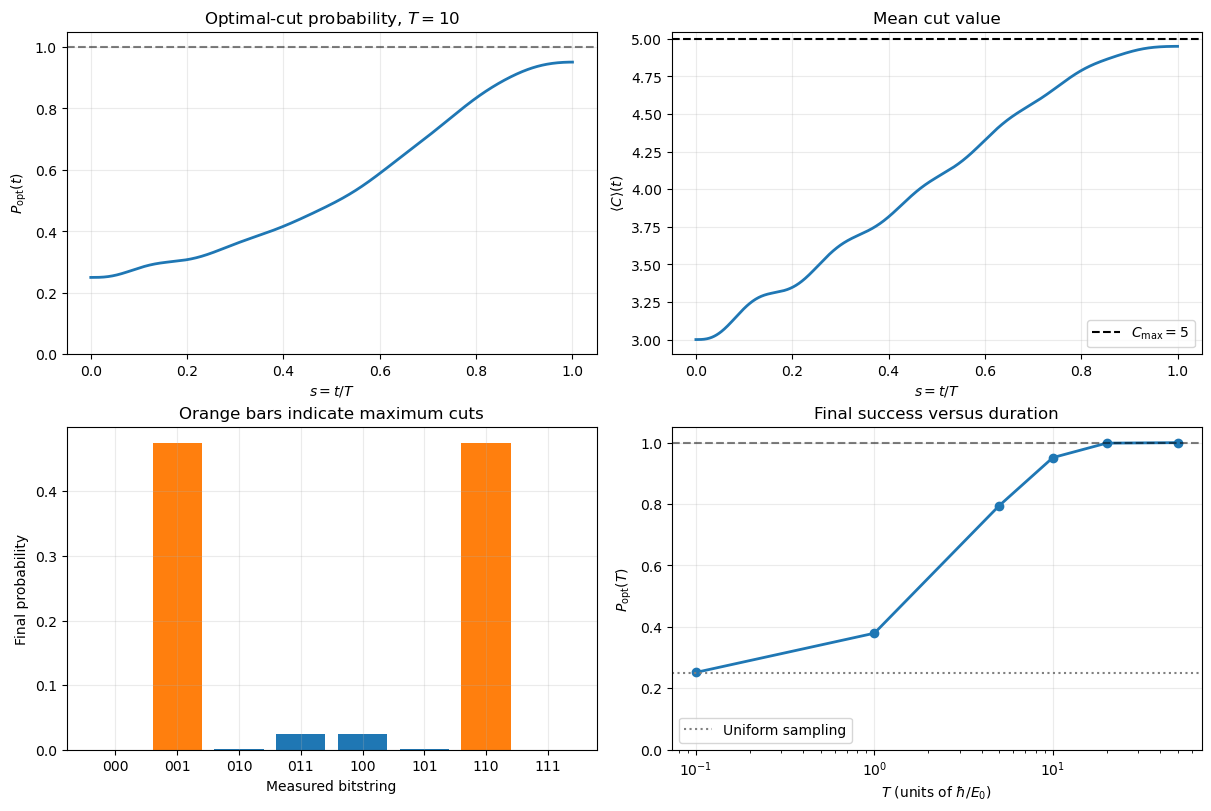

Exact minimum energy: -5.000000 E0
Ground-state bitstrings: 001, 110

       T        <H_P>(T)     Residual energy     P_ground(T)
     0.1     -3.01162259          1.98837741      0.25166206
     1.0     -3.81257066          1.18742934      0.37929259
     5.0     -4.77283928          0.22716072      0.79424669
    10.0     -4.94990704          0.05009296      0.95091961
    20.0     -4.99770496          0.00229504      0.99800666
    50.0     -4.99956125          0.00043875      0.99960164


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. Parameters and basis convention
# ============================================================
# Basis order: |000>, |001>, ..., |111>
# Spin 0 is the leftmost bit.
# Hamiltonian energies are measured in E0; times in hbar/E0.

N = 3
dim = 2**N

edges = [
    (0, 1, 1.0),
    (1, 2, 2.0),
    (0, 2, 3.0),
]

T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
T_plot = 10.0

s_grid = np.linspace(0.0, 1.0, 1001)
basis_labels = [format(n, f"0{N}b") for n in range(dim)]

# ============================================================
# 2. Spin operators
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    """Embed a single-spin operator in the N-spin Hilbert space."""
    result = np.array([[1.0]], dtype=complex)

    for j in range(N):
        result = np.kron(result, operator if j == site else I2)

    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

# ============================================================
# 3. Cut operator and annealing Hamiltonians
# ============================================================
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += 0.5 * weight * (I_full - Z_ops[i] @ Z_ops[j])

H_problem = -C_op
H_driver = -sum(X_ops)


def hamiltonian(s):
    """Linear interpolation from driver to problem Hamiltonian."""
    return (1.0 - s) * H_driver + s * H_problem


# Classical enumeration is used only to verify this small example.
cut_values = np.array([
    sum(
        weight
        for i, j, weight in edges
        if bits[i] != bits[j]
    )
    for bits in basis_labels
])

C_max = cut_values.max()
optimal_mask = np.isclose(cut_values, C_max)
optimal_labels = np.array(basis_labels)[optimal_mask]

assert np.allclose(np.diag(C_op).real, cut_values)
assert np.allclose(H_problem, H_problem.conj().T)

print("Classical verification")
for bits, cut in zip(basis_labels, cut_values):
    print(f"  {bits}: cut = {cut:.1f}")

print(f"\nMaximum cut: {C_max:.1f}")
print(f"Optimal bitstrings: {', '.join(optimal_labels)}")

# ============================================================
# 4. Initial state: ground state of H_driver
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)

assert np.allclose(H_driver @ psi_initial, -N * psi_initial)

initial_probabilities = np.abs(psi_initial)**2

print(
    f"\nInitial P_opt = "
    f"{initial_probabilities[optimal_mask].sum():.6f}"
)
print(
    f"Initial mean cut = "
    f"{cut_values @ initial_probabilities:.6f}"
)

# ============================================================
# 5. Closed-system evolution
# ============================================================
def run_annealing(T):
    """
    Solve dpsi/ds = -i T H(s) psi on s in [0, 1].
    T is the dimensionless total annealing duration.
    """

    def rhs(s, psi):
        return -1j * T * (hamiltonian(s) @ psi)

    solution = solve_ivp(
        rhs,
        t_span=(0.0, 1.0),
        y0=psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    states = solution.y  # shape: (dim, number of time points)
    probabilities = np.abs(states)**2

    # Do not renormalize: retain normalization error as a diagnostic.
    norm = probabilities.sum(axis=0)
    P_opt = probabilities[optimal_mask].sum(axis=0)
    mean_cut = cut_values @ probabilities

    return {
        "T": T,
        "s": solution.t,
        "time": T * solution.t,
        "states": states,
        "probabilities": probabilities,
        "norm": norm,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "norm_error": np.max(np.abs(norm - 1.0)),
    }


results = {T: run_annealing(T) for T in T_values}

print("\nFinal results")
print(f"{'T':>8} {'P_opt(T)':>14} {'Mean cut':>14} {'Max norm error':>18}")

for T, result in results.items():
    print(
        f"{T:8.1f}"
        f"{result['P_opt'][-1]:14.8f}"
        f"{result['mean_cut'][-1]:14.8f}"
        f"{result['norm_error']:18.2e}"
    )

# ============================================================
# 6. Plots
# ============================================================
selected = results[T_plot]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    constrained_layout=True,
)

# (a) Probability of measuring a maximum cut
ax = axes[0, 0]
ax.plot(selected["s"], selected["P_opt"], lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(t)$",
    title=fr"Optimal-cut probability, $T={T_plot:g}$",
    ylim=(0, 1.05),
)

# (b) Expected cut value
ax = axes[0, 1]
ax.plot(selected["s"], selected["mean_cut"], lw=2)
ax.axhline(
    C_max,
    color="black",
    ls="--",
    label=fr"$C_{{\max}}={C_max:g}$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\langle C\rangle(t)$",
    title="Mean cut value",
)
ax.legend()

# (c) Final measurement distribution
ax = axes[1, 0]
colors = [
    "tab:orange" if optimal else "tab:blue"
    for optimal in optimal_mask
]
ax.bar(
    basis_labels,
    selected["probabilities"][:, -1],
    color=colors,
)
ax.set(
    xlabel="Measured bitstring",
    ylabel="Final probability",
    title="Orange bars indicate maximum cuts",
)

# (d) Dependence on total annealing duration
ax = axes[1, 1]
durations = np.array(T_values)
final_success = np.array([
    results[T]["P_opt"][-1] for T in T_values
])

ax.semilogx(durations, final_success, "o-", lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(
    optimal_mask.sum() / dim,
    color="gray",
    ls=":",
    label="Uniform sampling",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Final success versus duration",
    ylim=(0, 1.05),
)
ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()


# Exact minimum of the final problem Hamiltonian
# H_problem is diagonal in the computational basis.
problem_energies = np.diag(H_problem).real
E_min = problem_energies.min()

ground_mask = np.isclose(problem_energies, E_min)
ground_bitstrings = np.array(basis_labels)[ground_mask]

print(f"Exact minimum energy: {E_min:.6f} E0")
print(f"Ground-state bitstrings: {', '.join(ground_bitstrings)}")

print(
    f"\n{'T':>8}"
    f"{'<H_P>(T)':>16}"
    f"{'Residual energy':>20}"
    f"{'P_ground(T)':>16}"
)

for T, result in results.items():
    p_final = result["probabilities"][:, -1]

    mean_energy = problem_energies @ p_final
    residual_energy = mean_energy - E_min
    ground_probability = p_final[ground_mask].sum()

    print(
        f"{T:8.1f}"
        f"{mean_energy:16.8f}"
        f"{residual_energy:20.8f}"
        f"{ground_probability:16.8f}"
    )

### Five-spin nearest-neighbour Ising chain: isolated quantum annealing

We consider an open chain of five spins, labelled $0,\ldots,4$,
with unit-weight nearest-neighbour edges:

$$
E=\{(0,1),(1,2),(2,3),(3,4)\}.
$$

There is no interaction between spins $4$ and $0$.

#### Cost function and problem Hamiltonian

For a configuration $\mathbf{z}$, with $z_i=(-1)^{b_i}=\pm1$,
the Max-Cut objective is

$$
C(\mathbf{z})=\frac12\sum_{i=0}^{3}(1-z_i z_{i+1}).
$$

We maximize this cost by minimizing

$$
H_P=-\widehat C
=-2I+\frac12\sum_{i=0}^{3}Z_iZ_{i+1}.
$$

Apart from the constant shift, this is an antiferromagnetic
nearest-neighbour Ising Hamiltonian with coupling $J=1/2$.
The shift preserves the relation $E=-C$.

Both alternating configurations cut all four edges:

$$
|01010\rangle,\qquad |10101\rangle.
$$

Therefore,

$$
C_{\max}=4,\qquad E_{\min}(H_P)=-4.
$$

The positive-weight open chain is unfrustrated and serves as
a dynamical benchmark rather than a difficult optimization instance.

#### Annealing protocol

The driver and initial state are

$$
H_D=-\sum_{i=0}^{4}X_i,\qquad
|\psi(0)\rangle=|+\rangle^{\otimes5}.
$$

We use a linear interpolation:

$$
H(s)=(1-s)H_D+sH_P,\qquad s=t/T\in[0,1].
$$

Energies are measured in $E_0$, and durations in $\hbar/E_0$.
In dimensionless variables, we integrate

$$
\frac{d|\psi\rangle}{ds}=-iT H(s)|\psi\rangle.
$$

The implementation applies the Hamiltonian directly to the state:
$H_P$ is diagonal, while each $X_i$ flips one bit. No dense
Hamiltonian matrices or instantaneous diagonalization are required.

#### Diagnostics

We calculate

$$
P_{\mathrm{opt}}(s)
=|\langle01010|\psi(s)\rangle|^2
+|\langle10101|\psi(s)\rangle|^2,
$$

$$
\langle C\rangle(s)=\langle\psi(s)|\widehat C|\psi(s)\rangle.
$$

Initially, all $32$ configurations have probability $1/32$, giving

$$
P_{\mathrm{opt}}(0)=\frac{2}{32}=\frac1{16},
\qquad
\langle C\rangle(0)=2.
$$

At the endpoint, $H(1)=H_P$, so

$$
\langle H_P\rangle_T=-\langle C\rangle_T,\qquad
E_{\mathrm{res}}(T)=\langle H_P\rangle_T-E_{\min}.
$$

We compare several durations and verify normalization throughout.
The reported minimum is independently obtained by enumerating
this small instance; it is not supplied to the dynamical solver.

Number of spins: 5
Hilbert-space dimension: 32
Edges: [(0, 1, 1.0), (1, 2, 1.0), (2, 3, 1.0), (3, 4, 1.0)]
Maximum cut: 4.0
Exact minimum problem energy: -4.0 E0
Optimal bitstrings: 01010, 10101

Initial P_opt: 0.062500
Initial mean cut: 2.000000

Final results
      T       P_opt         <C>      <H_P>/E0      E_res/E0    Norm error
    0.1    0.062917    2.003328     -2.003328      1.996672      6.51e-11
    1.0    0.103261    2.281840     -2.281840      1.718160      7.35e-11
    5.0    0.392413    3.228348     -3.228348      0.771652      3.63e-10
   10.0    0.643660    3.619324     -3.619324      0.380676      6.32e-10
   20.0    0.906924    3.906085     -3.906085      0.093915      8.40e-10
   50.0    0.995848    3.995768     -3.995768      0.004232      1.11e-09

Optimal configuration probabilities at T = 50:
  01010: 0.49792405
  10101: 0.49792405


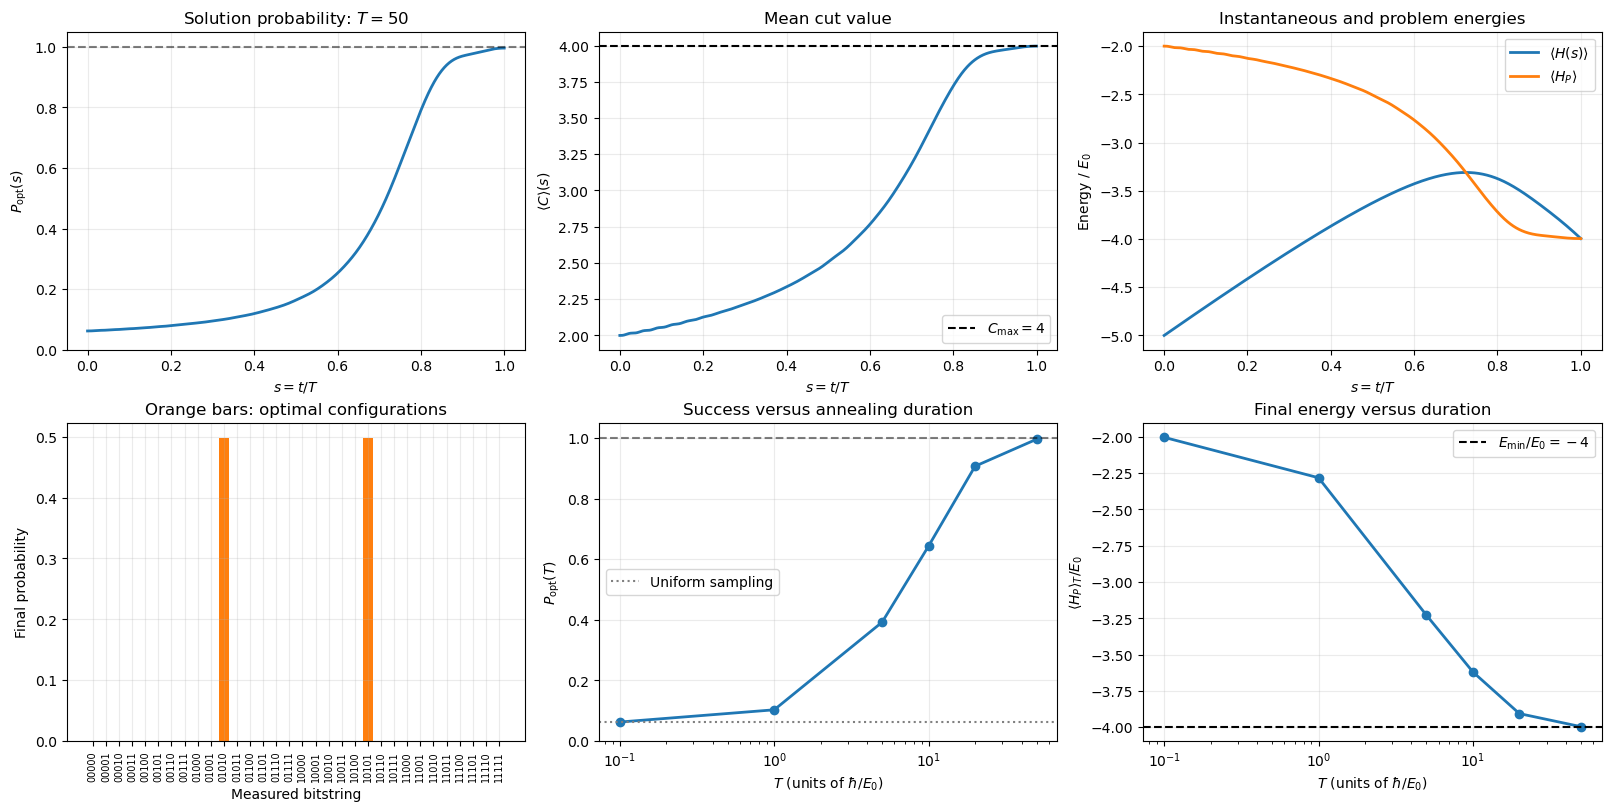

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. Five-spin open chain
# ============================================================
# Basis: |00000>, |00001>, ..., |11111>
# Spin 0 is the leftmost bit.
# Energy unit: E0. Time unit: hbar/E0.

N = 5
dim = 2**N

edges = [(i, i + 1, 1.0) for i in range(N - 1)]

T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
T_plot = 50.0
s_grid = np.linspace(0.0, 1.0, 1001)

indices = np.arange(dim)
basis_labels = np.array([
    format(n, f"0{N}b") for n in indices
])

# ============================================================
# 2. Diagonal problem energies from classical cut values
# ============================================================
cut_values = np.zeros(dim, dtype=float)

for i, j, weight in edges:
    bit_i = (indices >> (N - 1 - i)) & 1
    bit_j = (indices >> (N - 1 - j)) & 1
    cut_values += weight * (bit_i != bit_j)

problem_energies = -cut_values

C_max = cut_values.max()
E_min = problem_energies.min()
optimal_mask = np.isclose(cut_values, C_max)
optimal_labels = basis_labels[optimal_mask]

print(f"Number of spins: {N}")
print(f"Hilbert-space dimension: {dim}")
print(f"Edges: {edges}")
print(f"Maximum cut: {C_max:.1f}")
print(f"Exact minimum problem energy: {E_min:.1f} E0")
print(f"Optimal bitstrings: {', '.join(optimal_labels)}")

assert set(optimal_labels) == {"01010", "10101"}
assert np.isclose(C_max, 4.0)

# ============================================================
# 3. Matrix-free Hamiltonian action
# ============================================================
# X_i maps a basis index to the index with bit i flipped.
flip_indices = [
    indices ^ (1 << (N - 1 - i))
    for i in range(N)
]


def driver_action(psi):
    """Return H_D @ psi, where H_D = -sum_i X_i."""
    output = np.zeros_like(psi)

    for flipped in flip_indices:
        output -= psi[flipped]

    return output


def hamiltonian_action(s, psi):
    """Return H(s) @ psi without constructing a matrix."""
    return (
        (1.0 - s) * driver_action(psi)
        + s * problem_energies * psi
    )


# ============================================================
# 4. Initial driver ground state
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)

assert np.allclose(
    driver_action(psi_initial),
    -N * psi_initial,
)

initial_probabilities = np.abs(psi_initial)**2
P_uniform = optimal_mask.sum() / dim

print(f"\nInitial P_opt: {P_uniform:.6f}")
print(
    "Initial mean cut: "
    f"{cut_values @ initial_probabilities:.6f}"
)

# ============================================================
# 5. Unitary evolution
# ============================================================
def run_annealing(T):
    """Integrate dpsi/ds = -i T H(s) psi."""

    def rhs(s, psi):
        return -1j * T * hamiltonian_action(s, psi)

    solution = solve_ivp(
        rhs,
        t_span=(0.0, 1.0),
        y0=psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    states = solution.y
    probabilities = np.abs(states)**2

    # Preserve raw numerical results; do not renormalize.
    norm = probabilities.sum(axis=0)
    P_opt = probabilities[optimal_mask].sum(axis=0)
    mean_cut = cut_values @ probabilities

    # Expectation of the fixed final problem Hamiltonian.
    mean_problem_energy = problem_energies @ probabilities

    # Expectation of the actual instantaneous H(s).
    mean_total_energy = np.array([
        np.vdot(
            states[:, j],
            hamiltonian_action(s, states[:, j]),
        ).real
        for j, s in enumerate(solution.t)
    ])

    return {
        "T": T,
        "s": solution.t,
        "time": T * solution.t,
        "probabilities": probabilities,
        "norm": norm,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "mean_problem_energy": mean_problem_energy,
        "mean_total_energy": mean_total_energy,
        "final_residual_energy": mean_problem_energy[-1] - E_min,
        "norm_error": np.max(np.abs(norm - 1.0)),
    }


results = {
    T: run_annealing(T)
    for T in T_values
}

# ============================================================
# 6. Final diagnostics
# ============================================================
print("\nFinal results")
print(
    f"{'T':>7}"
    f"{'P_opt':>12}"
    f"{'<C>':>12}"
    f"{'<H_P>/E0':>14}"
    f"{'E_res/E0':>14}"
    f"{'Norm error':>14}"
)

for T, result in results.items():
    print(
        f"{T:7.1f}"
        f"{result['P_opt'][-1]:12.6f}"
        f"{result['mean_cut'][-1]:12.6f}"
        f"{result['mean_problem_energy'][-1]:14.6f}"
        f"{result['final_residual_energy']:14.6f}"
        f"{result['norm_error']:14.2e}"
    )

selected = results[T_plot]

print(f"\nOptimal configuration probabilities at T = {T_plot:g}:")
for label, probability in zip(
    basis_labels[optimal_mask],
    selected["probabilities"][optimal_mask, -1],
):
    print(f"  {label}: {probability:.8f}")

# ============================================================
# 7. Plots
# ============================================================
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8),
    constrained_layout=True,
)

# (a) Final-solution probability during a selected run
ax = axes[0, 0]
ax.plot(selected["s"], selected["P_opt"], lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(s)$",
    title=fr"Solution probability: $T={T_plot:g}$",
    ylim=(0, 1.05),
)

# (b) Mean cut during the ramp
ax = axes[0, 1]
ax.plot(selected["s"], selected["mean_cut"], lw=2)
ax.axhline(
    C_max,
    color="black",
    ls="--",
    label=fr"$C_{{\max}}={C_max:g}$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\langle C\rangle(s)$",
    title="Mean cut value",
)
ax.legend()

# (c) Energy expectations
ax = axes[0, 2]
ax.plot(
    selected["s"],
    selected["mean_total_energy"],
    lw=2,
    label=r"$\langle H(s)\rangle$",
)
ax.plot(
    selected["s"],
    selected["mean_problem_energy"],
    lw=2,
    label=r"$\langle H_P\rangle$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"Energy / $E_0$",
    title="Instantaneous and problem energies",
)
ax.legend()

# (d) Final bitstring distribution
ax = axes[1, 0]
colors = np.where(optimal_mask, "tab:orange", "tab:blue")

ax.bar(
    indices,
    selected["probabilities"][:, -1],
    color=colors,
)
ax.set_xticks(indices)
ax.set_xticklabels(basis_labels, rotation=90, fontsize=7)
ax.set(
    xlabel="Measured bitstring",
    ylabel="Final probability",
    title="Orange bars: optimal configurations",
)

# (e) Final success versus total duration
durations = np.array(T_values)
final_success = np.array([
    results[T]["P_opt"][-1] for T in T_values
])

ax = axes[1, 1]
ax.semilogx(durations, final_success, "o-", lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(
    P_uniform,
    color="gray",
    ls=":",
    label="Uniform sampling",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Success versus annealing duration",
    ylim=(0, 1.05),
)
ax.legend()

# (f) Final mean energy versus duration
final_energies = np.array([
    results[T]["mean_problem_energy"][-1]
    for T in T_values
])

ax = axes[1, 2]
ax.semilogx(durations, final_energies, "o-", lw=2)
ax.axhline(
    E_min,
    color="black",
    ls="--",
    label=fr"$E_{{\min}}/E_0={E_min:g}$",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$\langle H_P\rangle_T/E_0$",
    title="Final energy versus duration",
)
ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()

### Five-spin all-to-all Ising model: isolated quantum annealing

We label the spins $0,\ldots,4$ and connect every distinct pair.
This gives the complete graph $K_5$, containing

$$
|E|=\binom{5}{2}=10
$$

edges. All edge weights are $w_{ij}=1$.

Relative to the ordering $0,1,2,3,4$, the interactions are:

| Separation $|i-j|$ | Connected pairs |
|---|---|
| 1 | $(0,1),(1,2),(2,3),(3,4)$ |
| 2 | $(0,2),(1,3),(2,4)$ |
| 3 | $(0,3),(1,4)$ |
| 4 | $(0,4)$ |

Thus, we include all nearest-neighbour and longer-range pairs.
The separation identifies which sites interact; the coupling
strength is uniform rather than distance-dependent.

#### Cost function and Hamiltonian

The cut value of a spin configuration is

$$
C(\mathbf z)=\frac12\sum_{0\leq i<j\leq4}(1-z_i z_j),
\qquad z_i=(-1)^{b_i}.
$$

The corresponding problem Hamiltonian is

$$
H_P=-\widehat C
=-5I+\frac12\sum_{i<j}Z_iZ_j.
$$

This is an all-to-all antiferromagnetic Ising model with
pair coupling $J_{ij}=1/2$, apart from a constant energy shift.

For a partition containing $k$ vertices in one group and $5-k$
in the other, every cross-group pair contributes one:

$$
C=k(5-k).
$$

The maximum occurs for group sizes $2$ and $3$:

$$
C_{\max}=6,\qquad E_{\min}(H_P)=-6.
$$

The optimal bitstrings have Hamming weight $2$ or $3$.
There are $\binom52+\binom53=20$ optimal bitstrings,
representing $10$ distinct cuts after exchanging group labels.

The graph is frustrated: not all ten antiferromagnetic bonds
can be satisfied simultaneously.

#### Annealing dynamics

We use

$$
H_D=-\sum_{i=0}^{4}X_i,\qquad
|\psi(0)\rangle=|+\rangle^{\otimes5},
$$

and the linear schedule

$$
H(s)=(1-s)H_D+sH_P,\qquad s=t/T.
$$

Energies are measured in $E_0$ and durations in $\hbar/E_0$.
We integrate

$$
\frac{d|\psi\rangle}{ds}=-iT H(s)|\psi\rangle.
$$

The calculation uses the full $32$-dimensional spin basis
with matrix-free Hamiltonian application.

#### Diagnostics

We calculate the mean cut and the probability of measuring
any optimal configuration:

$$
\langle C\rangle(s)=
\sum_{\mathbf b}C(\mathbf b)|\langle\mathbf b|\psi(s)\rangle|^2,
$$

$$
P_{\mathrm{opt}}(s)=
\sum_{|\mathbf b|=2,3}|\langle\mathbf b|\psi(s)\rangle|^2.
$$

The initial uniform state gives

$$
\langle C\rangle(0)=5,\qquad
P_{\mathrm{opt}}(0)=\frac{20}{32}=\frac58.
$$

At the endpoint,

$$
\langle H_P\rangle_T=-\langle C\rangle_T,\qquad
E_{\mathrm{res}}=\langle H_P\rangle_T+6.
$$

This uniform complete graph is a symmetric benchmark with an
analytically known optimum, rather than a hard generic Max-Cut instance.
The pair couplings are not rescaled when moving from the open chain,
so the two models have different total interaction strengths.

Interactions by separation:
  Separation 1: [(0, 1), (1, 2), (2, 3), (3, 4)]
  Separation 2: [(0, 2), (1, 3), (2, 4)]
  Separation 3: [(0, 3), (1, 4)]
  Separation 4: [(0, 4)]

Hilbert-space dimension: 32
Number of edges: 10
Maximum cut: 6.0
Exact minimum energy: -6.0 E0
Number of optimal bitstrings: 20
Optimal bitstrings:
00011, 00101, 00110, 00111, 01001, 01010, 01011, 01100, 01101, 01110, 10001, 10010, 10011, 10100, 10101, 10110, 11000, 11001, 11010, 11100

Initial P_opt: 0.625000
Initial mean cut: 5.000000

Final results
      T       P_opt         <C>      <H_P>/E0      E_res/E0    Norm error
    0.1    0.627081    5.008299     -5.008299      0.991701      1.58e-10
    1.0    0.799853    5.562991     -5.562991      0.437009      2.61e-10
    5.0    0.974108    5.948145     -5.948145      0.051855      3.42e-10
   10.0    0.996045    5.992089     -5.992089      0.007911      4.01e-10
   20.0    0.999052    5.998104     -5.998104      0.001896      4.89e-10
   50.0    0.999850    5.

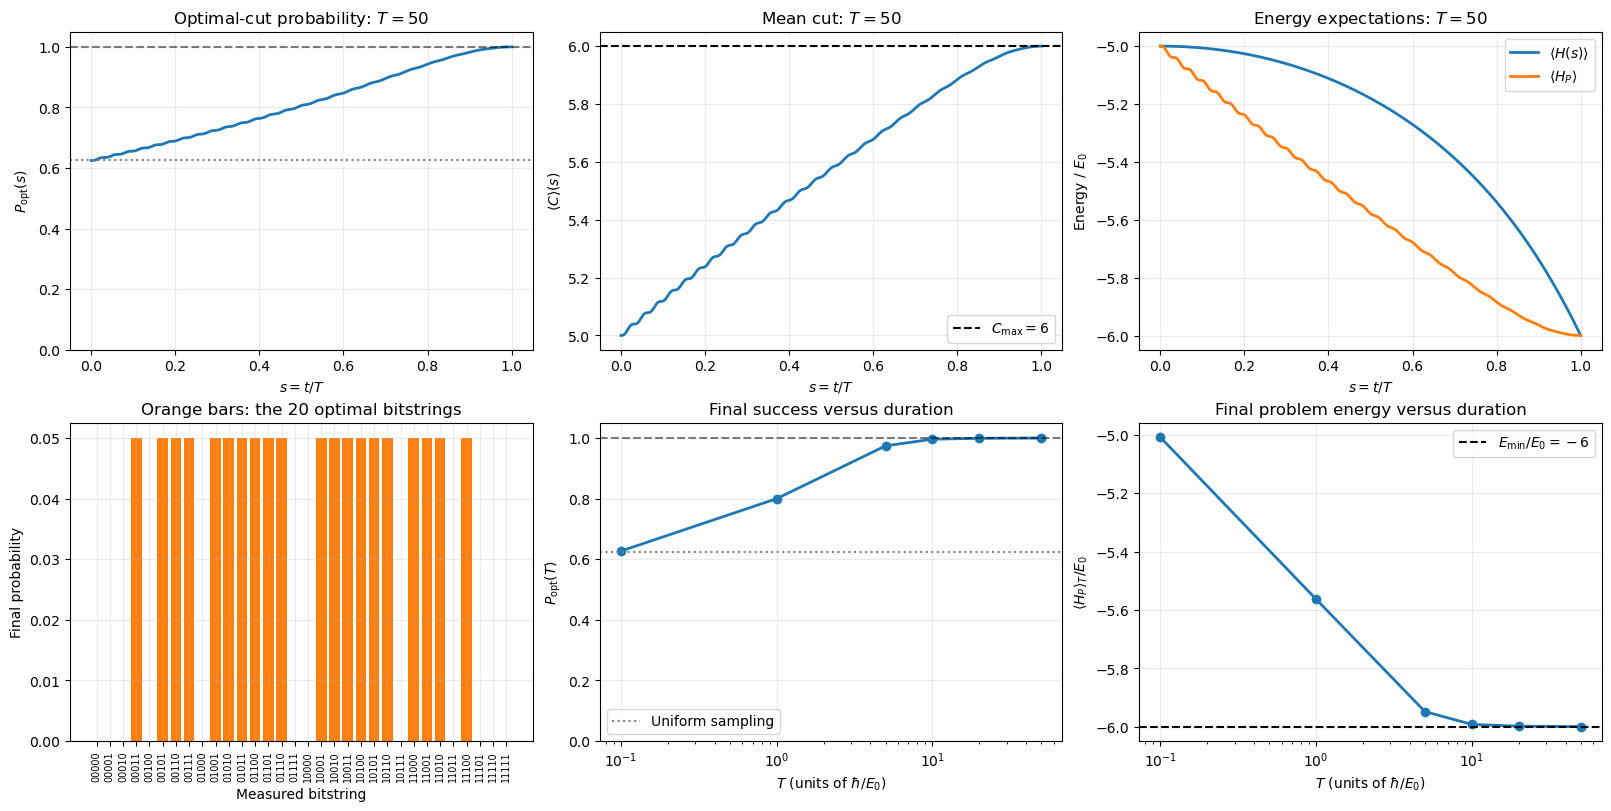

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.integrate import solve_ivp

# ============================================================
# 1. Parameters: all distinct spin pairs
# ============================================================
N = 5
dim = 2**N

# Four nearest-neighbour pairs and six longer-range pairs.
# All weights are equal; there is no distance decay.
edges = [
    (i, j, 1.0)
    for i, j in combinations(range(N), 2)
]

T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
T_plot = 50.0
s_grid = np.linspace(0.0, 1.0, 1001)

# Spin 0 is the leftmost bit.
indices = np.arange(dim)
basis_labels = np.array([
    format(n, f"0{N}b") for n in indices
])
hamming_weights = np.array([
    bits.count("1") for bits in basis_labels
])

print("Interactions by separation:")
for distance in range(1, N):
    pairs = [
        (i, j) for i, j, weight in edges
        if j - i == distance
    ]
    print(f"  Separation {distance}: {pairs}")

# ============================================================
# 2. Classical costs and diagonal problem Hamiltonian
# ============================================================
cut_values = np.zeros(dim)

for i, j, weight in edges:
    bit_i = (indices >> (N - 1 - i)) & 1
    bit_j = (indices >> (N - 1 - j)) & 1
    cut_values += weight * (bit_i != bit_j)

problem_energies = -cut_values
C_max = cut_values.max()
E_min = problem_energies.min()
optimal_mask = np.isclose(cut_values, C_max)
optimal_labels = basis_labels[optimal_mask]

# Independent analytical checks for uniform K5.
assert len(edges) == 10
assert np.allclose(
    cut_values,
    hamming_weights * (N - hamming_weights),
)
assert np.isclose(C_max, 6.0)
assert optimal_mask.sum() == 20

print(f"\nHilbert-space dimension: {dim}")
print(f"Number of edges: {len(edges)}")
print(f"Maximum cut: {C_max:.1f}")
print(f"Exact minimum energy: {E_min:.1f} E0")
print(f"Number of optimal bitstrings: {optimal_mask.sum()}")
print("Optimal bitstrings:")
print(", ".join(optimal_labels))

# ============================================================
# 3. Matrix-free Hamiltonian
# ============================================================
flip_indices = [
    indices ^ (1 << (N - 1 - i))
    for i in range(N)
]


def driver_action(psi):
    """H_D psi for H_D = -sum_i X_i."""
    output = np.zeros_like(psi)
    for flipped in flip_indices:
        output -= psi[flipped]
    return output


def hamiltonian_action(s, psi):
    """H(s) psi, with H_P diagonal."""
    return (
        (1.0 - s) * driver_action(psi)
        + s * problem_energies * psi
    )


psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)
P_uniform = optimal_mask.sum() / dim

assert np.allclose(
    driver_action(psi_initial), -N * psi_initial
)

print(f"\nInitial P_opt: {P_uniform:.6f}")
print(
    "Initial mean cut: "
    f"{cut_values @ np.abs(psi_initial)**2:.6f}"
)

# ============================================================
# 4. Isolated annealing
# ============================================================
def run_annealing(T):
    def rhs(s, psi):
        return -1j * T * hamiltonian_action(s, psi)

    solution = solve_ivp(
        rhs,
        (0.0, 1.0),
        psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    states = solution.y
    probabilities = np.abs(states)**2

    # Do not renormalize; monitor numerical error directly.
    norm = probabilities.sum(axis=0)
    mean_cut = cut_values @ probabilities
    mean_problem_energy = problem_energies @ probabilities

    mean_total_energy = np.array([
        np.vdot(
            states[:, j],
            hamiltonian_action(s, states[:, j]),
        ).real
        for j, s in enumerate(solution.t)
    ])

    return {
        "s": solution.t,
        "probabilities": probabilities,
        "P_opt": probabilities[optimal_mask].sum(axis=0),
        "mean_cut": mean_cut,
        "mean_problem_energy": mean_problem_energy,
        "mean_total_energy": mean_total_energy,
        "residual_energy": mean_problem_energy[-1] - E_min,
        "norm_error": np.max(np.abs(norm - 1.0)),
    }


results = {T: run_annealing(T) for T in T_values}

# ============================================================
# 5. Final results
# ============================================================
print("\nFinal results")
print(
    f"{'T':>7}"
    f"{'P_opt':>12}"
    f"{'<C>':>12}"
    f"{'<H_P>/E0':>14}"
    f"{'E_res/E0':>14}"
    f"{'Norm error':>14}"
)

for T, result in results.items():
    print(
        f"{T:7.1f}"
        f"{result['P_opt'][-1]:12.6f}"
        f"{result['mean_cut'][-1]:12.6f}"
        f"{result['mean_problem_energy'][-1]:14.6f}"
        f"{result['residual_energy']:14.6f}"
        f"{result['norm_error']:14.2e}"
    )

selected = results[T_plot]

# ============================================================
# 6. Plots
# ============================================================
fig, axes = plt.subplots(
    2, 3, figsize=(16, 8), constrained_layout=True
)

ax = axes[0, 0]
ax.plot(selected["s"], selected["P_opt"], lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(P_uniform, color="gray", ls=":")
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(s)$",
    title=fr"Optimal-cut probability: $T={T_plot:g}$",
    ylim=(0, 1.05),
)

ax = axes[0, 1]
ax.plot(selected["s"], selected["mean_cut"], lw=2)
ax.axhline(
    C_max, color="black", ls="--",
    label=fr"$C_{{\max}}={C_max:g}$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\langle C\rangle(s)$",
    title=fr"Mean cut: $T={T_plot:g}$",
)
ax.legend()

ax = axes[0, 2]
ax.plot(
    selected["s"], selected["mean_total_energy"],
    lw=2, label=r"$\langle H(s)\rangle$",
)
ax.plot(
    selected["s"], selected["mean_problem_energy"],
    lw=2, label=r"$\langle H_P\rangle$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"Energy / $E_0$",
    title=fr"Energy expectations: $T={T_plot:g}$",
)
ax.legend()

ax = axes[1, 0]
ax.bar(
    indices,
    selected["probabilities"][:, -1],
    color=np.where(optimal_mask, "tab:orange", "tab:blue"),
)
ax.set_xticks(indices)
ax.set_xticklabels(basis_labels, rotation=90, fontsize=7)
ax.set(
    xlabel="Measured bitstring",
    ylabel="Final probability",
    title="Orange bars: the 20 optimal bitstrings",
)

ax = axes[1, 1]
ax.semilogx(
    T_values,
    [results[T]["P_opt"][-1] for T in T_values],
    "o-", lw=2,
)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(
    P_uniform, color="gray", ls=":",
    label="Uniform sampling",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Final success versus duration",
    ylim=(0, 1.05),
)
ax.legend()

ax = axes[1, 2]
ax.semilogx(
    T_values,
    [results[T]["mean_problem_energy"][-1] for T in T_values],
    "o-", lw=2,
)
ax.axhline(
    E_min, color="black", ls="--",
    label=fr"$E_{{\min}}/E_0={E_min:g}$",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$\langle H_P\rangle_T/E_0$",
    title="Final problem energy versus duration",
)
ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()